# 🔥 PyTorch Mastery — One Notebook to Rule Them All

A single, hands-on path from tensors to a full training loop. Every section has a
**Concept**, a runnable **Demo**, and an **Exercise** with the solution right below.

**Three ideas that unlock PyTorch:**
1. **Tensor** — an n-dimensional array (like NumPy) that can live on a GPU and track gradients.
2. **Autograd** — PyTorch records operations on tensors with `requires_grad=True` and computes
   gradients automatically via `.backward()`.
3. **The training loop** — forward pass → loss → `backward()` → optimizer step → zero grads.
   Everything else is detail.

This notebook detects and uses your **Apple MPS GPU** when available, and keeps all data tiny
so every cell runs in seconds.

## Table of Contents
1. Setup, device & tensor anatomy
2. Creating tensors
3. Tensor math & operations
4. Indexing, slicing, reshaping
5. Broadcasting
6. The NumPy bridge
7. Device management (CPU / MPS / CUDA)
8. Autograd fundamentals
9. Controlling gradients (`no_grad`, `detach`, `zero_grad`)
10. Building models with `nn.Module`
11. Common layers
12. Loss functions
13. Optimizers & schedulers
14. The canonical training loop (linear regression)
15. Dataset & DataLoader
16. Classification with an MLP (+ loss/accuracy curves)
17. A small convolutional network
18. Saving & loading models
19. Evaluation & inference best practices
20. 🏆 Capstone — end-to-end classification on the GPU

## 1. Setup, Device & Tensor Anatomy

A tensor carries a `shape`, a `dtype`, and a `device`. Pick a single `device` up front and
send both your model and data to it.

In [1]:
import torch
import torch.nn as nn
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline

print("torch:", torch.__version__)

# Pick the best available device once, reuse everywhere
device = (
    "mps" if torch.backends.mps.is_available()
    else "cuda" if torch.cuda.is_available()
    else "cpu"
)
print("device:", device)

t = torch.tensor([[1.0, 2.0, 3.0],
                  [4.0, 5.0, 6.0]])
print(t)
print("shape :", t.shape)       # torch.Size([2, 3])
print("dtype :", t.dtype)       # torch.float32
print("device:", t.device)      # cpu (until we move it)
print("ndim  :", t.ndim, "| numel:", t.numel())

torch: 2.15.0
device: mps
tensor([[1., 2., 3.],
        [4., 5., 6.]])
shape : torch.Size([2, 3])
dtype : torch.float32
device: cpu
ndim  : 2 | numel: 6


**Exercise 1** — Make a 3×4 float tensor of all sevens and print its shape, dtype, and total element count.

In [2]:
# Your turn:

In [3]:
# Solution
x = torch.full((3, 4), 7.0)
print(x)
print(x.shape, x.dtype, x.numel())

tensor([[7., 7., 7., 7.],
        [7., 7., 7., 7.],
        [7., 7., 7., 7.]])
torch.Size([3, 4]) torch.float32 12


## 2. Creating Tensors

Many constructors mirror NumPy. Seeding makes random tensors reproducible.

In [4]:
torch.manual_seed(0)
print(torch.zeros(2, 3))
print(torch.ones(2, 3))
print(torch.arange(0, 10, 2))            # [0 2 4 6 8]
print(torch.linspace(0, 1, 5))
print(torch.eye(3))
print(torch.rand(2, 2))                  # uniform [0,1)
print(torch.randn(2, 2))                 # standard normal
print(torch.randint(0, 10, (2, 3)))      # ints in [0,10)
print(torch.zeros_like(torch.ones(2, 2)))
# set dtype / device at creation
print(torch.ones(2, 2, dtype=torch.float64))

tensor([[0., 0., 0.],
        [0., 0., 0.]])
tensor([[1., 1., 1.],
        [1., 1., 1.]])
tensor([0, 2, 4, 6, 8])
tensor([0.0000, 0.2500, 0.5000, 0.7500, 1.0000])
tensor([[1., 0., 0.],
        [0., 1., 0.],
        [0., 0., 1.]])
tensor([[0.4963, 0.7682],
        [0.0885, 0.1320]])
tensor([[-2.1788,  0.5684],
        [-1.0845, -1.3986]])
tensor([[6, 9, 8],
        [6, 6, 8]])
tensor([[0., 0.],
        [0., 0.]])
tensor([[1., 1.],
        [1., 1.]], dtype=torch.float64)


**Exercise 2** — Create a 4×4 identity matrix, and a 4×4 tensor of standard-normal noise (seed 1). Add them.

In [5]:
# Your turn:

In [6]:
# Solution
torch.manual_seed(1)
I = torch.eye(4)
noise = torch.randn(4, 4)
print((I + noise).round(decimals=2))

tensor([[-0.5300, -0.7500, -0.6500, -1.6100],
        [-0.1000,  0.3900, -0.9800, -1.6100],
        [-0.7100,  0.3000,  0.2200, -0.2500],
        [-0.2200,  1.6900,  0.2300,  1.4700]])


## 3. Tensor Math & Operations

Element-wise ops, reductions, and matrix multiply. Methods ending in `_` are **in-place**.

In [7]:
a = torch.tensor([1.0, 2.0, 3.0])
b = torch.tensor([4.0, 5.0, 6.0])
print(a + b, a * b, a ** 2, sep="\n")
print(torch.sqrt(torch.tensor([4.0, 9.0, 16.0])))

# Reductions (note: dim=, not axis=)
m = torch.arange(1, 13, dtype=torch.float32).reshape(3, 4)
print("sum        :", m.sum())
print("sum dim=0  :", m.sum(dim=0))      # collapse rows -> per column
print("mean dim=1 :", m.mean(dim=1))     # per row
print("max        :", m.max(), "argmax:", m.argmax())

# Matrix multiply: @ or matmul (NOT *, which is element-wise)
A = torch.randn(2, 3); B = torch.randn(3, 4)
print("A @ B shape:", (A @ B).shape)

# In-place ops mutate and save memory
c = torch.ones(3)
c.add_(5)           # c += 5
print("in-place:", c)

tensor([5., 7., 9.])
tensor([ 4., 10., 18.])
tensor([1., 4., 9.])
tensor([2., 3., 4.])
sum        : tensor(78.)
sum dim=0  : tensor([15., 18., 21., 24.])
mean dim=1 : tensor([ 2.5000,  6.5000, 10.5000])
max        : tensor(12.) argmax: tensor(11)
A @ B shape: torch.Size([2, 4])
in-place: tensor([6., 6., 6.])


**Exercise 3** — For a 3×4 tensor of 1..12, compute the column means and the index of the overall maximum.

In [8]:
# Your turn:

In [9]:
# Solution
m = torch.arange(1, 13, dtype=torch.float32).reshape(3, 4)
print("col means:", m.mean(dim=0))
print("argmax   :", m.argmax().item())

col means: tensor([5., 6., 7., 8.])
argmax   : 11


## 4. Indexing, Slicing, Reshaping

NumPy-style indexing. `view`/`reshape` change shape; `permute`/`transpose` reorder axes;
`unsqueeze`/`squeeze` add/remove size-1 dims.

In [10]:
x = torch.arange(12)
print(x[2:7])
print(x.reshape(3, 4))
print(x.view(2, 6))                 # view shares memory; reshape may copy
print(x.reshape(3, 4)[:, 1])        # a column
print(x.reshape(3, 4)[x.reshape(3, 4) > 5])   # boolean mask -> 1-D

g = torch.arange(6).reshape(2, 3)
print("transpose:\n", g.T)
print("unsqueeze:", g.unsqueeze(0).shape)   # (1,2,3)
print("squeeze  :", torch.ones(1, 3, 1).squeeze().shape)   # (3,)
print("permute  :", torch.randn(2, 3, 4).permute(2, 0, 1).shape)  # (4,2,3)

tensor([2, 3, 4, 5, 6])
tensor([[ 0,  1,  2,  3],
        [ 4,  5,  6,  7],
        [ 8,  9, 10, 11]])
tensor([[ 0,  1,  2,  3,  4,  5],
        [ 6,  7,  8,  9, 10, 11]])
tensor([1, 5, 9])
tensor([ 6,  7,  8,  9, 10, 11])
transpose:
 tensor([[0, 3],
        [1, 4],
        [2, 5]])
unsqueeze: torch.Size([1, 2, 3])
squeeze  : torch.Size([3])
permute  : torch.Size([4, 2, 3])


**Exercise 4** — Reshape `arange(24)` into shape (2, 3, 4), then permute it to (4, 3, 2).

In [11]:
# Your turn:

In [12]:
# Solution
t = torch.arange(24).reshape(2, 3, 4)
print(t.permute(2, 1, 0).shape)   # (4, 3, 2)

torch.Size([4, 3, 2])


## 5. Broadcasting

Same rules as NumPy: align shapes from the right; dims must be equal or one of them 1.

In [13]:
m = torch.arange(6, dtype=torch.float32).reshape(2, 3)
print(m + 100)                               # scalar
print(m + torch.tensor([10., 20., 30.]))     # (2,3)+(3,) per-row
print(m + torch.tensor([[100.], [200.]]))    # (2,3)+(2,1) per-column

# Standardize columns via broadcasting
x = torch.randn(5, 3)
xn = (x - x.mean(dim=0)) / x.std(dim=0)
print("col means ~0:", xn.mean(dim=0).round(decimals=4))

tensor([[100., 101., 102.],
        [103., 104., 105.]])
tensor([[10., 21., 32.],
        [13., 24., 35.]])
tensor([[100., 101., 102.],
        [203., 204., 205.]])
col means ~0: tensor([0., -0., 0.])


**Exercise 5** — Subtract the per-row mean from each row of a 4×5 random tensor; confirm new row means are ~0.

In [14]:
# Your turn:

In [15]:
# Solution
x = torch.randn(4, 5)
centered = x - x.mean(dim=1, keepdim=True)   # keepdim so (4,1) broadcasts
print(centered.mean(dim=1).round(decimals=5))

tensor([-0., 0., 0., 0.])


## 6. The NumPy Bridge

`torch.from_numpy` and `.numpy()` convert without copying on CPU — they **share memory**,
so a change to one shows in the other. Move to CPU first before `.numpy()` on a GPU tensor.

In [16]:
arr = np.array([1.0, 2.0, 3.0])
t = torch.from_numpy(arr)       # shares memory with arr
t.add_(100)
print("numpy changed too:", arr)   # [101. 102. 103.]

back = t.numpy()
print("back to numpy:", back, type(back))

# A GPU tensor must be moved to CPU before converting
g = torch.randn(3, device=device)
print("to numpy via cpu:", g.cpu().numpy())

numpy changed too: [101. 102. 103.]
back to numpy: [101. 102. 103.] <class 'numpy.ndarray'>


to numpy via cpu: [ 0.28194502 -0.46787655  1.6783983 ]


**Exercise 6** — Create a NumPy array `[0,1,2,3]`, bridge it to a tensor, multiply the tensor in place by 10, and show the NumPy array also changed.

In [17]:
# Your turn:

In [18]:
# Solution
arr = np.arange(4).astype(np.float32)
t = torch.from_numpy(arr)
t.mul_(10)
print("tensor:", t)
print("numpy :", arr)   # also [0 10 20 30]

tensor: tensor([ 0., 10., 20., 30.])
numpy : [ 0. 10. 20. 30.]


## 7. Device Management

Move tensors/models with `.to(device)`. Operations require all operands on the **same** device.
MPS (Apple) and most layers only support `float32` — keep that as your default.

In [19]:
cpu_t = torch.randn(3, 3)
dev_t = cpu_t.to(device)
print("moved to:", dev_t.device)

# A quick timing comparison on a matmul
import time
size = 1000
x_cpu = torch.randn(size, size)
x_dev = x_cpu.to(device)

t0 = time.perf_counter(); _ = x_cpu @ x_cpu; cpu_t_ms = (time.perf_counter()-t0)*1000
t0 = time.perf_counter(); r = x_dev @ x_dev
if device != "cpu":
    getattr(torch, device).synchronize() if hasattr(torch, device) else None
dev_t_ms = (time.perf_counter()-t0)*1000
print(f"matmul {size}x{size}: cpu {cpu_t_ms:.1f} ms | {device} {dev_t_ms:.1f} ms")
print("(for tiny tensors, CPU can win — GPUs shine on large batched work)")

moved to: mps:0
matmul 1000x1000: cpu 1.4 ms | mps 71.3 ms
(for tiny tensors, CPU can win — GPUs shine on large batched work)


**Exercise 7** — Create two 2×2 tensors on `device`, multiply them, and move the result back to CPU as a NumPy array.

In [20]:
# Your turn:

In [21]:
# Solution
a = torch.randn(2, 2, device=device)
b = torch.randn(2, 2, device=device)
print((a @ b).cpu().numpy())

[[-2.646006   -3.6269128 ]
 [ 1.2894939   0.33268818]]


## 8. Autograd Fundamentals

Set `requires_grad=True` and PyTorch builds a graph of your operations. Call `.backward()`
on a scalar to populate `.grad` on each leaf tensor with ∂output/∂input.

In [22]:
# Simplest example: y = x^2, dy/dx = 2x
x = torch.tensor(3.0, requires_grad=True)
y = x ** 2
y.backward()
print("x:", x.item(), "y:", y.item(), "dy/dx:", x.grad.item())   # 6.0

# Vector input, scalar output
w = torch.tensor([1.0, 2.0, 3.0], requires_grad=True)
loss = (w ** 2).sum()        # d/dw_i = 2 w_i
loss.backward()
print("gradient:", w.grad)   # [2. 4. 6.]

x: 3.0 y: 9.0 dy/dx: 6.0
gradient: tensor([2., 4., 6.])


In [23]:
# A tiny manual linear layer to see gradients flow
torch.manual_seed(0)
x = torch.randn(4, 3)
W = torch.randn(3, 1, requires_grad=True)
b = torch.zeros(1, requires_grad=True)
target = torch.randn(4, 1)

pred = x @ W + b
loss = ((pred - target) ** 2).mean()
loss.backward()
print("loss:", loss.item())
print("dL/dW:\n", W.grad)
print("dL/db:", b.grad)

loss: 0.3919924795627594
dL/dW:
 tensor([[ 0.6655],
        [ 0.0015],
        [-1.2026]])
dL/db: tensor([1.1560])


**Exercise 8** — Let `f(x) = 3x³ + 2x` at x=2. Compute f and df/dx with autograd (the analytic derivative is 9x²+2 = 38).

In [24]:
# Your turn:

In [25]:
# Solution
x = torch.tensor(2.0, requires_grad=True)
f = 3 * x ** 3 + 2 * x
f.backward()
print("f(2):", f.item(), "| df/dx:", x.grad.item())   # 28.0, 38.0

f(2): 28.0 | df/dx: 38.0


## 9. Controlling Gradients

- Gradients **accumulate** — you must `zero_grad()` each step.
- `torch.no_grad()` disables tracking (inference, faster, less memory).
- `.detach()` returns a tensor cut off from the graph.

In [26]:
w = torch.tensor([1.0, 2.0], requires_grad=True)

# accumulation: two backward passes add up unless cleared
(w.sum()).backward();  print("after 1st:", w.grad)   # [1. 1.]
(w.sum()).backward();  print("after 2nd:", w.grad)   # [2. 2.]  <-- accumulated!
w.grad.zero_();        print("after zero:", w.grad)   # [0. 0.]

# no_grad: no graph is built
with torch.no_grad():
    y = w * 2
print("y.requires_grad inside no_grad:", y.requires_grad)   # False

# detach: snapshot outside the graph
z = (w * 3).detach()
print("z.requires_grad:", z.requires_grad)                  # False

after 1st: tensor([1., 1.])
after 2nd: tensor([2., 2.])
after zero: tensor([0., 0.])
y.requires_grad inside no_grad: False
z.requires_grad: False


**Exercise 9** — With `x = tensor([2.,3.], requires_grad=True)`, run `backward` on `x.sum()` twice **without** zeroing, then once more after zeroing. Print grad each time.

In [27]:
# Your turn:

In [28]:
# Solution
x = torch.tensor([2.0, 3.0], requires_grad=True)
x.sum().backward(); print(x.grad)    # [1. 1.]
x.sum().backward(); print(x.grad)    # [2. 2.]
x.grad.zero_()
x.sum().backward(); print(x.grad)    # [1. 1.]

tensor([1., 1.])
tensor([2., 2.])
tensor([1., 1.])


## 10. Building Models with `nn.Module`

Subclass `nn.Module`, define layers in `__init__`, and the computation in `forward`.
Layers automatically register their learnable parameters.

In [29]:
class MLP(nn.Module):
    def __init__(self, in_dim, hidden, out_dim):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(in_dim, hidden),
            nn.ReLU(),
            nn.Linear(hidden, out_dim),
        )

    def forward(self, x):
        return self.net(x)

model = MLP(4, 16, 3).to(device)
print(model)
n_params = sum(p.numel() for p in model.parameters())
print("trainable params:", n_params)

# A forward pass on a dummy batch
dummy = torch.randn(5, 4, device=device)
print("output shape:", model(dummy).shape)   # (5, 3)

MLP(
  (net): Sequential(
    (0): Linear(in_features=4, out_features=16, bias=True)
    (1): ReLU()
    (2): Linear(in_features=16, out_features=3, bias=True)
  )
)
trainable params: 131
output shape: torch.Size([5, 3])


**Exercise 10** — Build a 2-layer MLP mapping 10 features → 32 hidden → 1 output with a `Tanh` activation, move it to `device`, and run a forward pass on a batch of 8.

In [30]:
# Your turn:

In [31]:
# Solution
class Net(nn.Module):
    def __init__(self):
        super().__init__()
        self.fc1 = nn.Linear(10, 32)
        self.act = nn.Tanh()
        self.fc2 = nn.Linear(32, 1)
    def forward(self, x):
        return self.fc2(self.act(self.fc1(x)))

net = Net().to(device)
out = net(torch.randn(8, 10, device=device))
print(out.shape)   # (8, 1)

torch.Size([8, 1])


## 11. Common Layers

The building blocks you'll reach for most often.

In [32]:
batch = torch.randn(8, 16)

print("Linear      :", nn.Linear(16, 4)(batch).shape)          # (8,4)
print("ReLU        :", nn.ReLU()(batch).shape)
print("Dropout     :", nn.Dropout(0.5)(batch).shape)
print("BatchNorm1d :", nn.BatchNorm1d(16)(batch).shape)
print("LayerNorm   :", nn.LayerNorm(16)(batch).shape)

# Conv / pooling expect (N, C, H, W)
img = torch.randn(8, 3, 32, 32)
conv = nn.Conv2d(in_channels=3, out_channels=6, kernel_size=3, padding=1)
print("Conv2d      :", conv(img).shape)                        # (8,6,32,32)
print("MaxPool2d   :", nn.MaxPool2d(2)(conv(img)).shape)       # (8,6,16,16)

# Embedding: integer ids -> dense vectors
emb = nn.Embedding(num_embeddings=100, embedding_dim=8)
print("Embedding   :", emb(torch.randint(0, 100, (4, 5))).shape)  # (4,5,8)

Linear      : torch.Size([8, 4])


ReLU        : torch.Size([8, 16])
Dropout     : torch.Size([8, 16])
BatchNorm1d : torch.Size([8, 16])
LayerNorm   : torch.Size([8, 16])
Conv2d      : torch.Size([8, 6, 32, 32])


MaxPool2d   : torch.Size([8, 6, 16, 16])
Embedding   : torch.Size([4, 5, 8])


**Exercise 11** — Pass a batch of 4 single-channel 28×28 images through a `Conv2d(1→8, kernel 3, padding 1)` then `MaxPool2d(2)`, and print the output shape.

In [33]:
# Your turn:

In [34]:
# Solution
imgs = torch.randn(4, 1, 28, 28)
conv = nn.Conv2d(1, 8, kernel_size=3, padding=1)
pool = nn.MaxPool2d(2)
print(pool(conv(imgs)).shape)   # (4, 8, 14, 14)

torch.Size([4, 8, 14, 14])


## 12. Loss Functions

Match the loss to the task. **Important:** `CrossEntropyLoss` expects raw **logits** (no softmax)
and integer class targets; `BCEWithLogitsLoss` expects raw logits for binary problems.

In [35]:
# Regression
pred = torch.tensor([2.5, 0.0, 2.1]); target = torch.tensor([3.0, -0.5, 2.0])
print("MSE:", nn.MSELoss()(pred, target).item())
print("L1 :", nn.L1Loss()(pred, target).item())

# Multi-class classification: logits (N, C) + integer labels (N,)
logits = torch.tensor([[2.0, 0.5, 0.1], [0.1, 0.2, 3.0]])
labels = torch.tensor([0, 2])
print("CrossEntropy:", nn.CrossEntropyLoss()(logits, labels).item())

# Binary classification: single logit per sample
bin_logits = torch.tensor([1.5, -2.0, 0.3])
bin_targets = torch.tensor([1.0, 0.0, 1.0])
print("BCEWithLogits:", nn.BCEWithLogitsLoss()(bin_logits, bin_targets).item())

MSE: 0.17000000178813934
L1 : 0.36666664481163025
CrossEntropy: 0.21319009363651276
BCEWithLogits: 0.29423218965530396


**Exercise 12** — Given logits for 3 samples over 4 classes and labels `[2, 0, 3]`, compute the cross-entropy loss.

In [36]:
# Your turn:

In [37]:
# Solution
torch.manual_seed(0)
logits = torch.randn(3, 4)
labels = torch.tensor([2, 0, 3])
print(nn.CrossEntropyLoss()(logits, labels).item())

2.5383472442626953


## 13. Optimizers & Schedulers

An optimizer updates parameters from their gradients. A scheduler adjusts the learning rate
over time. The standard choice is `Adam`; `SGD` with momentum is the classic baseline.

In [38]:
model = nn.Linear(4, 1)
opt = torch.optim.Adam(model.parameters(), lr=0.01)
print("optimizer:", type(opt).__name__, "| lr:", opt.param_groups[0]['lr'])

sched = torch.optim.lr_scheduler.StepLR(opt, step_size=2, gamma=0.5)
lrs = []
for epoch in range(6):
    opt.step()          # (no real grad here; just to advance state)
    sched.step()
    lrs.append(round(opt.param_groups[0]['lr'], 5))
print("lr schedule over epochs:", lrs)   # halves every 2 epochs

optimizer: Adam | lr: 0.01
lr schedule over epochs: [0.01, 0.005, 0.005, 0.0025, 0.0025, 0.00125]


**Exercise 13** — Create an SGD optimizer (lr 0.1, momentum 0.9) over a `Linear(3,1)`'s params and print its initial learning rate and momentum.

In [39]:
# Your turn:

In [40]:
# Solution
m = nn.Linear(3, 1)
opt = torch.optim.SGD(m.parameters(), lr=0.1, momentum=0.9)
pg = opt.param_groups[0]
print("lr:", pg['lr'], "| momentum:", pg['momentum'])

lr: 0.1 | momentum: 0.9


## 14. The Canonical Training Loop

Memorize this five-step rhythm — it is the heart of every PyTorch model:

```
for each batch:
    1. pred = model(x)        # forward
    2. loss = criterion(...)  # measure error
    3. optimizer.zero_grad()  # clear old grads
    4. loss.backward()        # backprop
    5. optimizer.step()       # update weights
```

Here we fit a line `y = 2x + 1` from noisy data.

learned: y = 2.000 x + 1.019   (true: 2x + 1)


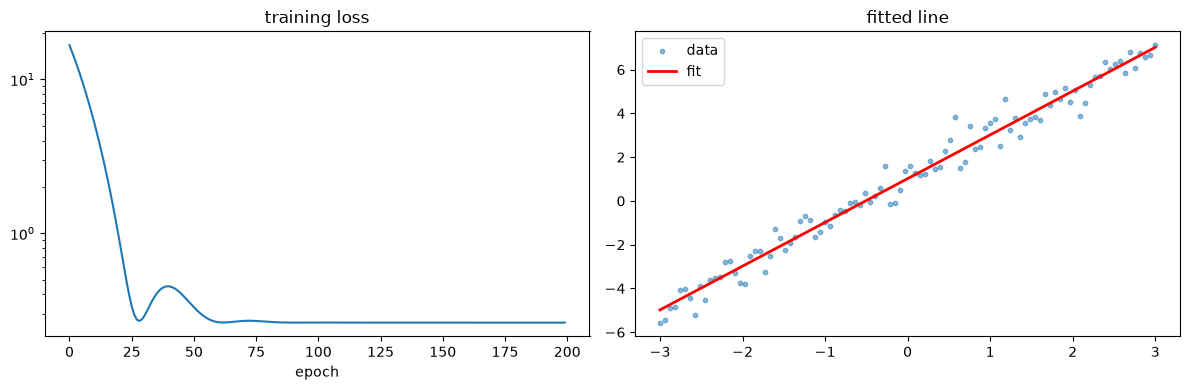

In [41]:
torch.manual_seed(0)
# Data: y = 2x + 1 + noise
X = torch.linspace(-3, 3, 100).reshape(-1, 1)
y = 2 * X + 1 + 0.5 * torch.randn_like(X)
X, y = X.to(device), y.to(device)

model = nn.Linear(1, 1).to(device)
criterion = nn.MSELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.1)

losses = []
for epoch in range(200):
    pred = model(X)
    loss = criterion(pred, y)
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()
    losses.append(loss.item())

w = model.weight.item(); b = model.bias.item()
print(f"learned: y = {w:.3f} x + {b:.3f}   (true: 2x + 1)")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(losses); axes[0].set_title("training loss"); axes[0].set_xlabel("epoch"); axes[0].set_yscale('log')
axes[1].scatter(X.cpu(), y.cpu(), s=10, alpha=0.5, label="data")
axes[1].plot(X.cpu(), model(X).detach().cpu(), 'r', lw=2, label="fit")
axes[1].legend(); axes[1].set_title("fitted line")
plt.tight_layout(); plt.show()

**Exercise 14** — Fit `y = -3x + 2` from noisy data using the same five-step loop (150 epochs). Print the learned slope and intercept.

In [42]:
# Your turn:

In [43]:
# Solution
torch.manual_seed(1)
X = torch.linspace(-2, 2, 80).reshape(-1, 1).to(device)
y = (-3 * X + 2 + 0.3 * torch.randn_like(X)).to(device)
model = nn.Linear(1, 1).to(device)
crit = nn.MSELoss(); opt = torch.optim.Adam(model.parameters(), lr=0.1)
for _ in range(150):
    loss = crit(model(X), y)
    opt.zero_grad(); loss.backward(); opt.step()
print(f"slope {model.weight.item():.3f}, intercept {model.bias.item():.3f}  (true -3, 2)")

slope -2.974, intercept 2.004  (true -3, 2)


## 15. Dataset & DataLoader

Real training iterates over **mini-batches**. `TensorDataset` wraps tensors; `DataLoader`
handles batching, shuffling, and iteration.

In [44]:
from torch.utils.data import TensorDataset, DataLoader

X = torch.randn(100, 3)
y = torch.randn(100, 1)
ds = TensorDataset(X, y)
loader = DataLoader(ds, batch_size=16, shuffle=True)

print("dataset size:", len(ds))
print("num batches :", len(loader))
for xb, yb in loader:
    print("first batch:", xb.shape, yb.shape)
    break

# A typical mini-batch epoch
total = 0
for xb, yb in loader:
    total += xb.shape[0]
print("samples seen in one epoch:", total)

dataset size: 100
num batches : 7
first batch: torch.Size([16, 3]) torch.Size([16, 1])
samples seen in one epoch: 100


**Exercise 15** — Wrap 50 samples of 4 features in a `DataLoader` (batch size 8, shuffled) and print the number of batches and the size of the last batch.

In [45]:
# Your turn:

In [46]:
# Solution
from torch.utils.data import TensorDataset, DataLoader
ds = TensorDataset(torch.randn(50, 4), torch.randint(0, 2, (50,)))
loader = DataLoader(ds, batch_size=8, shuffle=True)
sizes = [xb.shape[0] for xb, _ in loader]
print("num batches:", len(sizes), "| last batch size:", sizes[-1])   # 7 batches, last = 2

num batches: 7 | last batch size: 2


## 16. Classification with an MLP

A complete classifier on a synthetic 2-class problem (two interleaving clusters), with a
train/validation split, mini-batch training, and loss/accuracy curves.

final validation accuracy: 0.925


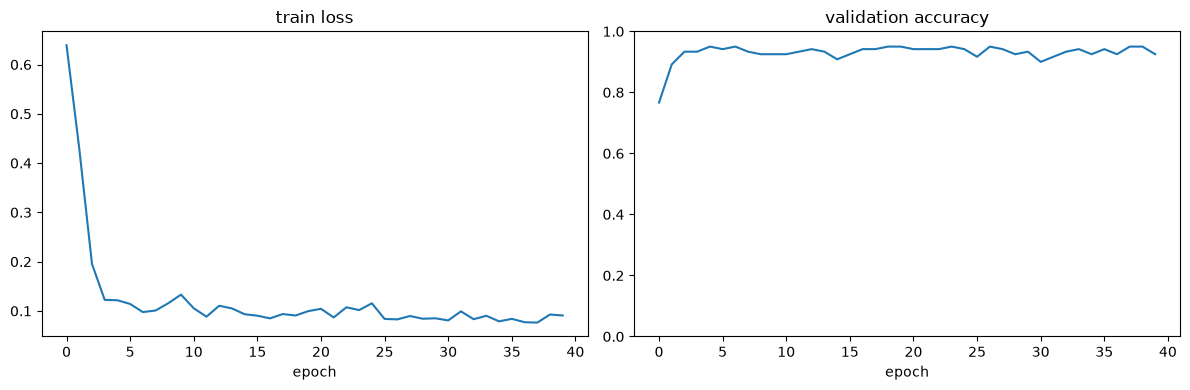

In [47]:
from torch.utils.data import TensorDataset, DataLoader

# Build a non-linear 2-class dataset (two concentric rings)
rng = np.random.default_rng(0)
n = 600
r = rng.uniform(0, 1, n)
theta = rng.uniform(0, 2 * np.pi, n)
label = (r > 0.5).astype(np.int64)                 # inner ring vs outer ring
r_noisy = r + rng.normal(0, 0.05, n)
Xnp = np.stack([r_noisy * np.cos(theta), r_noisy * np.sin(theta)], axis=1).astype(np.float32)

X = torch.from_numpy(Xnp)
yt = torch.from_numpy(label)

# 80/20 split
perm = torch.randperm(n)
ntr = int(0.8 * n)
tr_idx, va_idx = perm[:ntr], perm[ntr:]
train_ds = TensorDataset(X[tr_idx], yt[tr_idx])
val_ds = TensorDataset(X[va_idx], yt[va_idx])
train_loader = DataLoader(train_ds, batch_size=32, shuffle=True)
val_loader = DataLoader(val_ds, batch_size=64)

clf = nn.Sequential(nn.Linear(2, 32), nn.ReLU(),
                    nn.Linear(32, 32), nn.ReLU(),
                    nn.Linear(32, 2)).to(device)
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(clf.parameters(), lr=0.01)

def accuracy(loader):
    clf.eval()
    correct = total = 0
    with torch.no_grad():
        for xb, yb in loader:
            xb, yb = xb.to(device), yb.to(device)
            pred = clf(xb).argmax(dim=1)
            correct += (pred == yb).sum().item(); total += yb.numel()
    return correct / total

hist = {"loss": [], "val_acc": []}
for epoch in range(40):
    clf.train()
    ep_loss = 0.0
    for xb, yb in train_loader:
        xb, yb = xb.to(device), yb.to(device)
        loss = criterion(clf(xb), yb)
        optimizer.zero_grad(); loss.backward(); optimizer.step()
        ep_loss += loss.item() * xb.shape[0]
    hist["loss"].append(ep_loss / len(train_ds))
    hist["val_acc"].append(accuracy(val_loader))

print(f"final validation accuracy: {hist['val_acc'][-1]:.3f}")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(hist["loss"]); axes[0].set_title("train loss"); axes[0].set_xlabel("epoch")
axes[1].plot(hist["val_acc"]); axes[1].set_title("validation accuracy"); axes[1].set_xlabel("epoch")
axes[1].set_ylim(0, 1)
plt.tight_layout(); plt.show()

**Exercise 16** — Report the classifier's accuracy on the **training** set using the `accuracy()` helper, and compare it to the validation accuracy.

In [48]:
# Your turn:

In [49]:
# Solution
print("train acc:", round(accuracy(train_loader), 3))
print("val   acc:", round(hist['val_acc'][-1], 3))

train acc: 0.954
val   acc: 0.925


## 17. A Small Convolutional Network

CNNs excel at images. We build tiny synthetic 1×8×8 images whose class depends on whether
they contain a vertical or a horizontal stripe, and train a small CNN to tell them apart.

CNN validation accuracy: 1.000


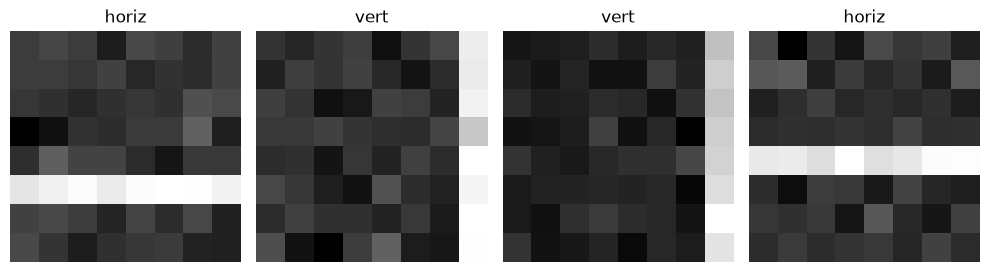

In [50]:
from torch.utils.data import TensorDataset, DataLoader

def make_stripe_images(n, seed):
    rng = np.random.default_rng(seed)
    imgs = rng.normal(0, 0.3, (n, 1, 8, 8)).astype(np.float32)
    labels = rng.integers(0, 2, n)
    for i, lab in enumerate(labels):
        col_or_row = rng.integers(0, 8)
        if lab == 0:                       # vertical stripe
            imgs[i, 0, :, col_or_row] += 3.0
        else:                              # horizontal stripe
            imgs[i, 0, col_or_row, :] += 3.0
    return torch.from_numpy(imgs), torch.from_numpy(labels.astype(np.int64))

Xtr, ytr = make_stripe_images(800, 0)
Xva, yva = make_stripe_images(200, 1)
train_loader = DataLoader(TensorDataset(Xtr, ytr), batch_size=32, shuffle=True)
val_loader = DataLoader(TensorDataset(Xva, yva), batch_size=64)

class SmallCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(1, 8, kernel_size=3, padding=1), nn.ReLU(),
            nn.MaxPool2d(2),                      # 8x8 -> 4x4
            nn.Conv2d(8, 16, kernel_size=3, padding=1), nn.ReLU(),
            nn.MaxPool2d(2),                      # 4x4 -> 2x2
        )
        self.classifier = nn.Sequential(nn.Flatten(), nn.Linear(16 * 2 * 2, 2))

    def forward(self, x):
        return self.classifier(self.features(x))

cnn = SmallCNN().to(device)
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(cnn.parameters(), lr=0.01)

for epoch in range(8):
    cnn.train()
    for xb, yb in train_loader:
        xb, yb = xb.to(device), yb.to(device)
        loss = criterion(cnn(xb), yb)
        optimizer.zero_grad(); loss.backward(); optimizer.step()

cnn.eval()
correct = total = 0
with torch.no_grad():
    for xb, yb in val_loader:
        xb, yb = xb.to(device), yb.to(device)
        correct += (cnn(xb).argmax(1) == yb).sum().item(); total += yb.numel()
print(f"CNN validation accuracy: {correct/total:.3f}")

# Show a couple of example images
fig, axes = plt.subplots(1, 4, figsize=(10, 3))
for ax, img, lab in zip(axes, Xva[:4], yva[:4]):
    ax.imshow(img[0], cmap='gray'); ax.set_title("vert" if lab == 0 else "horiz")
    ax.axis('off')
plt.tight_layout(); plt.show()

**Exercise 17** — Count the total number of trainable parameters in the `SmallCNN` (hint: sum `p.numel()` over `cnn.parameters()`).

In [51]:
# Your turn:

In [52]:
# Solution
print("params:", sum(p.numel() for p in cnn.parameters() if p.requires_grad))

params: 1378


## 18. Saving & Loading Models

The recommended way: save the `state_dict` (the learned weights), not the whole object.
Rebuild the model architecture, then load the weights into it.

In [53]:
import tempfile, os
tmp = tempfile.mkdtemp()
path = os.path.join(tmp, "model.pt")

# Save
torch.save(cnn.state_dict(), path)
print("saved:", os.path.getsize(path), "bytes")

# Load into a fresh instance
reloaded = SmallCNN().to(device)
reloaded.load_state_dict(torch.load(path, map_location=device))
reloaded.eval()

# Verify identical predictions on a sample batch
xb = Xva[:16].to(device)
with torch.no_grad():
    same = torch.equal(cnn(xb).argmax(1), reloaded(xb).argmax(1))
print("reloaded model matches original:", same)

saved: 8445 bytes
reloaded model matches original: True


**Exercise 18** — Save the `SmallCNN` weights, load them into a new instance, and confirm the predictions match on the first 8 validation images.

In [54]:
# Your turn:

In [55]:
# Solution
import tempfile, os
p = os.path.join(tempfile.mkdtemp(), "cnn.pt")
torch.save(cnn.state_dict(), p)
m2 = SmallCNN().to(device); m2.load_state_dict(torch.load(p, map_location=device)); m2.eval()
xb = Xva[:8].to(device)
with torch.no_grad():
    print("match:", torch.equal(cnn(xb).argmax(1), m2(xb).argmax(1)))

match: True


## 19. Evaluation & Inference Best Practices

Three habits that prevent subtle bugs:
1. Call `model.eval()` so layers like Dropout/BatchNorm behave in inference mode.
2. Wrap inference in `torch.no_grad()` — faster, less memory, no accidental graph.
3. Convert logits to probabilities with `softmax` (multi-class) or `sigmoid` (binary) only
   at the very end, for reporting — never feed softmax into `CrossEntropyLoss`.

In [56]:
cnn.eval()
sample = Xva[:5].to(device)
with torch.no_grad():
    logits = cnn(sample)
    probs = torch.softmax(logits, dim=1)
    preds = probs.argmax(dim=1)

print("logits:\n", logits.cpu().round(decimals=2))
print("probabilities:\n", probs.cpu().round(decimals=3))
print("predicted classes:", preds.cpu().tolist())
print("true classes     :", yva[:5].tolist())

logits:
 tensor([[-11.7300,  11.8500],
        [  7.2900,  -6.1200],
        [  7.5600,  -6.4000],
        [-13.5200,  15.1600],
        [-12.2000,  14.8700]])
probabilities:
 tensor([[0., 1.],
        [1., 0.],
        [1., 0.],
        [0., 1.],
        [0., 1.]])
predicted classes: [1, 0, 0, 1, 1]
true classes     : [1, 0, 0, 1, 1]


**Exercise 19** — For the first validation image, print the model's predicted class and its confidence (the max softmax probability).

In [57]:
# Your turn:

In [58]:
# Solution
cnn.eval()
with torch.no_grad():
    p = torch.softmax(cnn(Xva[:1].to(device)), dim=1)
conf, cls = p.max(dim=1)
print(f"predicted class {cls.item()} with confidence {conf.item():.3f}")

predicted class 1 with confidence 1.000


## 20. 🏆 Capstone — End-to-End Classification on the GPU

Put it all together: build a dataset, split it, train a model on `device` with mini-batches,
track train and validation metrics, and visualize the results. Try before peeking.

**Task.** Generate a 3-class dataset (three Gaussian blobs in 2-D). Build an MLP classifier,
train it for 50 epochs with Adam, and produce: (1) a loss curve, (2) a validation-accuracy
curve, and (3) a scatter of the validation set colored by **predicted** class.

In [59]:
# Your turn:

final validation accuracy: 0.993


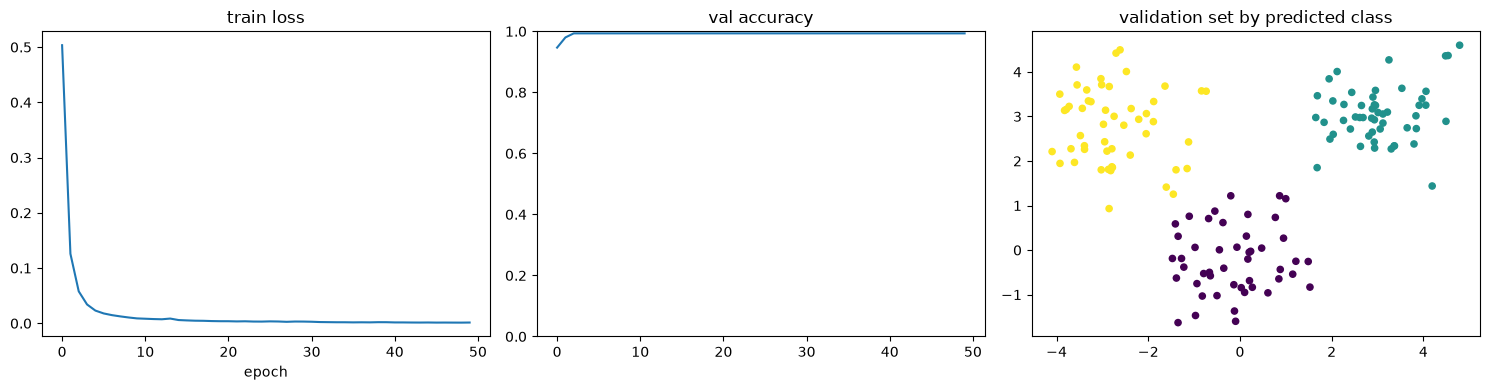

In [60]:
# Solution
from torch.utils.data import TensorDataset, DataLoader

# 1) Three-blob dataset
rng = np.random.default_rng(7)
centers = np.array([[0, 0], [3, 3], [-3, 3]], dtype=np.float32)
per = 250
Xnp = np.vstack([c + rng.normal(0, 0.8, (per, 2)) for c in centers]).astype(np.float32)
ynp = np.repeat(np.arange(3), per).astype(np.int64)

X = torch.from_numpy(Xnp); y = torch.from_numpy(ynp)
perm = torch.randperm(len(X)); ntr = int(0.8 * len(X))
tr, va = perm[:ntr], perm[ntr:]
train_loader = DataLoader(TensorDataset(X[tr], y[tr]), batch_size=32, shuffle=True)
Xva, yva = X[va].to(device), y[va].to(device)

# 2) Model + training
model = nn.Sequential(nn.Linear(2, 32), nn.ReLU(), nn.Linear(32, 3)).to(device)
crit = nn.CrossEntropyLoss(); opt = torch.optim.Adam(model.parameters(), lr=0.01)

loss_hist, acc_hist = [], []
for epoch in range(50):
    model.train(); ep = 0.0
    for xb, yb in train_loader:
        xb, yb = xb.to(device), yb.to(device)
        loss = crit(model(xb), yb)
        opt.zero_grad(); loss.backward(); opt.step()
        ep += loss.item() * xb.shape[0]
    loss_hist.append(ep / ntr)
    model.eval()
    with torch.no_grad():
        acc_hist.append((model(Xva).argmax(1) == yva).float().mean().item())

print(f"final validation accuracy: {acc_hist[-1]:.3f}")

# 3) Visualize
with torch.no_grad():
    val_pred = model(Xva).argmax(1).cpu().numpy()

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
axes[0].plot(loss_hist); axes[0].set_title("train loss"); axes[0].set_xlabel("epoch")
axes[1].plot(acc_hist); axes[1].set_title("val accuracy"); axes[1].set_ylim(0, 1)
sc = axes[2].scatter(Xva[:, 0].cpu(), Xva[:, 1].cpu(), c=val_pred, cmap='viridis', s=20)
axes[2].set_title("validation set by predicted class")
plt.tight_layout(); plt.show()

---
## 🎓 You Made It

If you can reproduce the training loop in section 14 from memory and explain each of the five
steps, you have the core of PyTorch. Where to go next:

- Swap the synthetic data for a real dataset via `torchvision.datasets` (MNIST, CIFAR-10).
- Add validation-based early stopping and checkpointing.
- Learn `torch.nn.functional`, custom `Dataset` classes, and learning-rate schedulers in depth.
- Explore transfer learning with a pretrained `torchvision.models` backbone.

Keep the exercises. Delete the solution cells and redo them in a week — spaced repetition turns
practice into mastery.